<a href="https://colab.research.google.com/github/xuannn0212/lepidoptera-benchmark-analysis/blob/main/P2_MobileNetV2_Revise.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import os

os.environ['KAGGLE_USERNAME'] = ""
os.environ['KAGGLE_KEY'] = ""  # Paste your Kaggle key here

print("Kaggle credentials successfully configured!")

Kaggle credentials successfully configured!


In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
!kaggle datasets download -d gpiosenka/butterfly-images40-species
!pip install split-folders

import zipfile
import shutil
import os
import splitfolders

# 1. Extract
if os.path.exists('master_dataset'): shutil.rmtree('master_dataset')
if os.path.exists('raw_dataset'): shutil.rmtree('raw_dataset')

zip_ref = zipfile.ZipFile('butterfly-images40-species.zip', 'r')
zip_ref.extractall('raw_dataset')
zip_ref.close()

# 2. Merge
master_dir = 'master_dataset'
os.makedirs(master_dir, exist_ok=True)

def merge_folders(source_dir, prefix):
    if os.path.exists(source_dir):
        for species_folder in os.listdir(source_dir):
            src_path = os.path.join(source_dir, species_folder)
            dest_path = os.path.join(master_dir, species_folder)
            if not os.path.exists(dest_path): os.makedirs(dest_path)
            for img_file in os.listdir(src_path):
                shutil.move(os.path.join(src_path, img_file), os.path.join(dest_path, f"{prefix}_{img_file}"))

merge_folders('raw_dataset/train', 'train')
merge_folders('raw_dataset/valid', 'valid')
merge_folders('raw_dataset/test', 'test')

# 3. Split Locally for GPU Speed
output_local_path = '/content/Dataset'
splitfolders.ratio('master_dataset', output=output_local_path, seed=42, ratio=(.7, .15, .15), move=False)

Dataset URL: https://www.kaggle.com/datasets/gpiosenka/butterfly-images40-species
License(s): CC0-1.0
100% 399M/399M [00:02<00:00, 183MB/s]



Copying files: 13594 files [00:02, 5818.02 files/s]


In [4]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

tf.random.set_seed(42)

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
NUM_CLASSES = 100

TRAIN_DIR = '/content/Dataset/train'
VAL_DIR = '/content/Dataset/val'
TEST_DIR = '/content/Dataset/test'

# Identical augmentation to ResNet-50 for fair comparison
train_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    rotation_range=30,
    width_shift_range=0.1,
    height_shift_range=0.1,
    shear_range=0.15,
    zoom_range=0.2,
    horizontal_flip=True,
    fill_mode='nearest'
)

val_test_datagen = ImageDataGenerator(preprocessing_function=preprocess_input)

train_generator = train_datagen.flow_from_directory(
    TRAIN_DIR, target_size=IMG_SIZE, batch_size=BATCH_SIZE, class_mode='categorical', seed=42)

val_generator = val_test_datagen.flow_from_directory(
    VAL_DIR, target_size=IMG_SIZE, batch_size=BATCH_SIZE, class_mode='categorical', seed=42)

Found 9473 images belonging to 100 classes.
Found 1986 images belonging to 100 classes.


In [5]:
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout
from tensorflow.keras.models import Model
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping

EPOCHS_STAGE1 = 15
checkpoint_path = "/content/drive/MyDrive/P2_MobileNetV2_Tuned_Model.keras"

# Build MobileNetV2 Architecture
base_model = MobileNetV2(weights='imagenet', include_top=False, input_shape=(224, 224, 3))
base_model.trainable = False

x = base_model.output
x = GlobalAveragePooling2D()(x)
# TUNING 1: Increased Dropout to 0.4 to prevent overfitting the smaller feature maps
x = Dropout(0.4)(x)
predictions = Dense(NUM_CLASSES, activation='softmax')(x)

model = Model(inputs=base_model.input, outputs=predictions)

print("--- STAGE 1: Training Classification Head ---")
# TUNING 2: Switch to AdamW for better weight regularization
optimizer = tf.keras.optimizers.AdamW(learning_rate=1e-3, weight_decay=1e-4)

model.compile(optimizer=optimizer, loss='categorical_crossentropy', metrics=['accuracy'])

callbacks_stage1 = [
    ModelCheckpoint(checkpoint_path, monitor='val_accuracy', save_best_only=True, verbose=1),
    EarlyStopping(monitor='val_loss', patience=4, restore_best_weights=True, verbose=1)
]

history1 = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=EPOCHS_STAGE1,
    callbacks=callbacks_stage1
)

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
--- STAGE 1: Training Classification Head ---
Epoch 1/15
297/297 ━━━━━━━━━━━━━━━━━━━━ 0s 435ms/step - accuracy: 0.3047 - loss: 3.2477
Epoch 1: val_accuracy improved from None to 0.78902, saving model to /content/drive/MyDrive/P2_MobileNetV2_Tuned_Model.keras

Epoch 1: finished saving model to /content/drive/MyDrive/P2_MobileNetV2_Tuned_Model.keras
297/297 ━━━━━━━━━━━━━━━━━━━━ 157s 488ms/step - accuracy: 0.5070 - loss: 2.1902 - val_accuracy: 0.7890 - val_loss: 0.9859
Epoch 2/15
297/297 ━━━━━━━━━━━━━━━━━━━━ 0s 405ms/step - accuracy: 0.7654 - loss: 0.9613
Epoch 2: val_accuracy improved from 0.78902 to 0.83938, saving model to /content/drive/MyDrive/P2_MobileNetV2_Tuned_Model.keras

Epoch 2: finished saving model to /content/drive/MyDrive/P2_MobileNetV2_Tuned_Model.keras
297/297 ━━━━━━━━━━━━━━━━━━━━ 126s 423ms/step - accuracy: 0.7756 - loss: 0.8926 - val_accuracy: 0.8394 - val_loss: 0.6764
Epoch 3/15
297/297 ━━━━━━━━━━━━━━━━━━━━ 0s 393ms/ste

In [6]:
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping, LearningRateScheduler
import tensorflow as tf
import math

# Increased epochs slightly to allow the cosine curve to complete smoothly
EPOCHS_STAGE2 = 40

print("--- STAGE 2: Deep Fine-Tuning with Cosine Decay ---")

# MODIFICATION 1: Unfreeze 100% of the network
# By setting this to True and removing the loop that froze the first 50 layers,
# you allow all 154 layers of MobileNetV2 to adapt to fine-grained butterfly textures.
base_model.trainable = True

# TUNING 4: Smooth Cosine Decay Schedule
def cosine_decay(epoch, lr):
    initial_lr = 1e-4
    return initial_lr * 0.5 * (1 + math.cos(math.pi * epoch / EPOCHS_STAGE2))

lr_scheduler = LearningRateScheduler(cosine_decay, verbose=1)

model.compile(
    optimizer=tf.keras.optimizers.AdamW(learning_rate=1e-4, weight_decay=1e-5),
    # MODIFICATION 2: Apply Label Smoothing (0.1)
    # This prevents the lightweight network from becoming overconfident during training,
    # forcing it to generalize better on the unseen test set.
    loss=tf.keras.losses.CategoricalCrossentropy(label_smoothing=0.1),
    metrics=['accuracy']
)

callbacks_stage2 = [
    ModelCheckpoint(checkpoint_path, monitor='val_accuracy', save_best_only=True, verbose=1),
    EarlyStopping(monitor='val_loss', patience=7, restore_best_weights=True, verbose=1),
    lr_scheduler
]

history2 = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=EPOCHS_STAGE2,
    callbacks=callbacks_stage2
)

--- STAGE 2: Deep Fine-Tuning with Cosine Decay ---

Epoch 1: LearningRateScheduler setting learning rate to 0.0001.
Epoch 1/40
297/297 ━━━━━━━━━━━━━━━━━━━━ 0s 515ms/step - accuracy: 0.7548 - loss: 1.9531
Epoch 1: val_accuracy improved from None to 0.87865, saving model to /content/drive/MyDrive/P2_MobileNetV2_Tuned_Model.keras

Epoch 1: finished saving model to /content/drive/MyDrive/P2_MobileNetV2_Tuned_Model.keras
297/297 ━━━━━━━━━━━━━━━━━━━━ 221s 553ms/step - accuracy: 0.8212 - loss: 1.6139 - val_accuracy: 0.8787 - val_loss: 2.1648 - learning_rate: 1.0000e-04

Epoch 2: LearningRateScheduler setting learning rate to 9.98458666866564e-05.
Epoch 2/40
297/297 ━━━━━━━━━━━━━━━━━━━━ 0s 429ms/step - accuracy: 0.9008 - loss: 1.3169
Epoch 2: val_accuracy improved from 0.87865 to 0.89376, saving model to /content/drive/MyDrive/P2_MobileNetV2_Tuned_Model.keras

Epoch 2: finished saving model to /content/drive/MyDrive/P2_MobileNetV2_Tuned_Model.keras
297/297 ━━━━━━━━━━━━━━━━━━━━ 133s 448ms/step

In [7]:
import numpy as np
import time
from sklearn.metrics import classification_report
from tensorflow.keras.models import load_model

print("Loading best model weights...")
best_model = load_model(checkpoint_path)

test_generator = val_test_datagen.flow_from_directory(
    TEST_DIR,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)

print("\nEvaluating model on unseen test data...")
# 1. Start the timer right before prediction
start_time = time.time()

# 2. Run the prediction
predictions = best_model.predict(test_generator)

# 3. Stop the timer the exact millisecond it finishes
end_time = time.time()

# 4. Calculate and print the speed metrics
total_time = end_time - start_time
print(f"\n--- INFERENCE SPEED BENCHMARK ---")
print(f"Total Inference Time (2,135 images): {total_time:.2f} seconds")
print(f"Average Time per Image: {(total_time / 2135) * 1000:.2f} milliseconds")

y_pred = np.argmax(predictions, axis=1)
y_true = test_generator.classes

print("\n--- MACRO METRICS & CLASSIFICATION REPORT ---")
print(classification_report(y_true, y_pred, target_names=list(test_generator.class_indices.keys())))

Loading best model weights...
Found 2135 images belonging to 100 classes.

Evaluating model on unseen test data...
67/67 ━━━━━━━━━━━━━━━━━━━━ 13s 148ms/step

--- INFERENCE SPEED BENCHMARK ---
Total Inference Time (2,135 images): 13.61 seconds
Average Time per Image: 6.38 milliseconds

--- MACRO METRICS & CLASSIFICATION REPORT ---
                           precision    recall  f1-score   support

                   ADONIS       1.00      0.90      0.95        21
AFRICAN GIANT SWALLOWTAIL       1.00      1.00      1.00        19
           AMERICAN SNOOT       0.95      1.00      0.97        18
                    AN 88       1.00      1.00      1.00        21
                  APPOLLO       1.00      0.91      0.95        22
     ARCIGERA FLOWER MOTH       1.00      1.00      1.00        23
                    ATALA       1.00      1.00      1.00        24
               ATLAS MOTH       0.91      0.95      0.93        22
 BANDED ORANGE HELICONIAN       1.00      0.91      0.95        

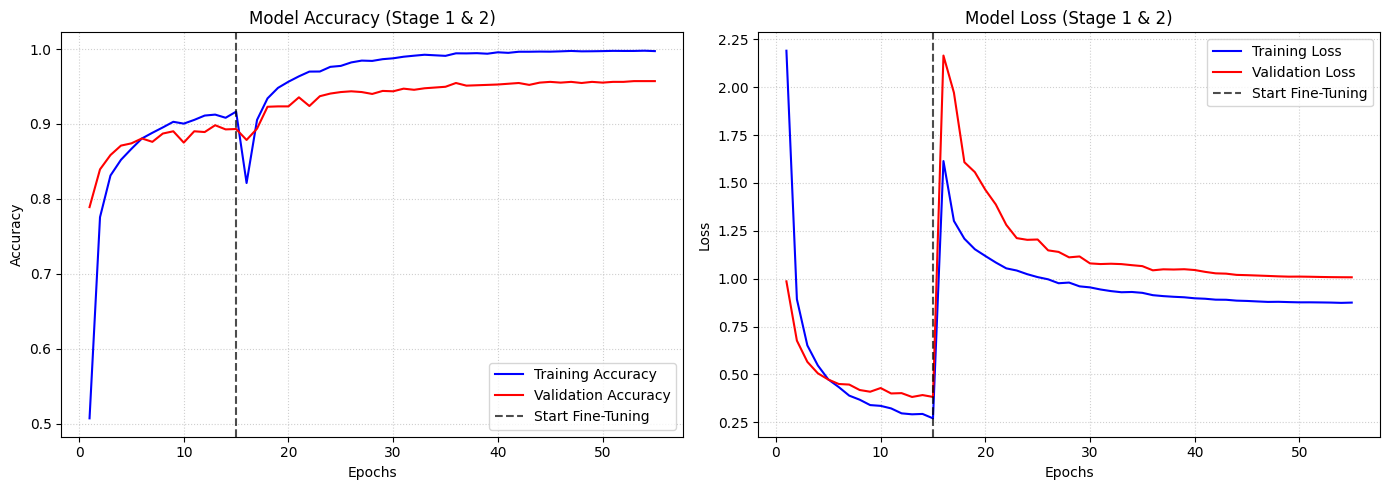

In [8]:
import matplotlib.pyplot as plt

# 1. Combine the history data from Stage 1 and Stage 2
acc = history1.history['accuracy'] + history2.history['accuracy']
val_acc = history1.history['val_accuracy'] + history2.history['val_accuracy']
loss = history1.history['loss'] + history2.history['loss']
val_loss = history1.history['val_loss'] + history2.history['val_loss']

# 2. Set up the epochs timeline
epochs = range(1, len(acc) + 1)
stage1_epochs = len(history1.history['accuracy'])

# 3. Create a wide figure to hold two side-by-side graphs
plt.figure(figsize=(14, 5))

# --- GRAPH 1: ACCURACY ---
plt.subplot(1, 2, 1)
plt.plot(epochs, acc, 'b-', label='Training Accuracy')
plt.plot(epochs, val_acc, 'r-', label='Validation Accuracy')
# Add a vertical dotted line to show where Fine-Tuning started
plt.axvline(x=stage1_epochs, color='k', linestyle='--', alpha=0.7, label='Start Fine-Tuning')
plt.title('Model Accuracy (Stage 1 & 2)')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend(loc='lower right')
plt.grid(True, linestyle=':', alpha=0.6)

# --- GRAPH 2: LOSS ---
plt.subplot(1, 2, 2)
plt.plot(epochs, loss, 'b-', label='Training Loss')
plt.plot(epochs, val_loss, 'r-', label='Validation Loss')
# Add a vertical dotted line to show where Fine-Tuning started
plt.axvline(x=stage1_epochs, color='k', linestyle='--', alpha=0.7, label='Start Fine-Tuning')
plt.title('Model Loss (Stage 1 & 2)')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend(loc='upper right')
plt.grid(True, linestyle=':', alpha=0.6)

# 4. Display the graphs
plt.tight_layout()
plt.show()